# License Plate Detection with a Fine-Tuned YOLOv8n

**Course:** Deep Learning, BSE-7A  |  **Task:** single-class object detection (`license_plate`)

**Team**
| Member | ID |
|---|---|
| Hafiz Umar | 23K-0035 |
| Naveed Ahmed | 23K-3025 |
| Imam Ali Mehdi | 23K-3029 |

**Dataset:** [`keremberke/license-plate-object-detection`](https://huggingface.co/datasets/keremberke/license-plate-object-detection) (Hugging Face Hub, Roboflow export; 6,179 train / 1,768 val / 885 test images)
**Pretrained model:** `yolov8n.pt` (Ultralytics, COCO)

### Notebook map
| # | Section | What it does |
|---|---|---|
| 0 | Configuration | Paths, seeds, run switches |
| 1 | Setup | Install and import libraries |
| 2 | Dataset | Load, inspect, visualise |
| 3 | Preprocessing | COCO boxes to YOLO labels, `data.yaml`, sanity checks |
| 4 | Model | Load pretrained YOLOv8n |
| 5 | Baselines | Epoch-1 reference and optional from-scratch baseline |
| 6 | Training | Fine-tune (guarded by `RUN_TRAINING`) |
| 7 | Training curves | Plot `results.csv` |
| 8 | Test evaluation | Precision, recall, mAP on the held-out test split |
| 9 | Error analysis | False negatives, false positives, loose boxes, per-subset rates |
| 10 | Inference demo | Predictions on test images |
| 11 | OCR extension | EasyOCR on detected plates (out of scope) |
| 12 | Summary and disclosure | Results, limitations, AI-use note |

### How to run
1. **Quick grading run (no training):** set `RUN_TRAINING = False`, provide `best.pt` at `WEIGHTS_PATH` (see section 0), then *Run all*.
2. **Full reproduction:** set `RUN_TRAINING = True` (about 72 min on a Colab T4), then *Run all*.

Runtime: GPU recommended (Colab: *Runtime, Change runtime type, T4 GPU*).

## 0. Configuration

In [21]:
import os, random
from pathlib import Path

# ---- Run switches -----------------------------------------------------------
RUN_TRAINING          = False   # True: fine-tune (about 72 min on a T4). False: load existing weights.
RUN_BASELINE_SCRATCH  = False   # True: also train YOLOv8n from random init (Baseline B, optional, slow).
RUN_OCR_DEMO          = True    # Out-of-scope extension (needs `easyocr`).
USE_GOOGLE_DRIVE      = False   # Colab only: mount Drive to persist weights/results.

# ---- Hyper-parameters (as used for the reported results) ---------------------
SEED, EPOCHS, IMGSZ, BATCH, PATIENCE = 0, 50, 640, 16, 10
CONF_THRES = 0.25               # confidence threshold for predictions / error analysis
IOU_MATCH  = 0.50               # IoU used to match predictions to ground truth

# ---- Paths -------------------------------------------------------------------
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ROOT        = Path("/content") if IN_COLAB else Path.cwd()
DATASET_DIR = ROOT / "license_plate_dataset"          # YOLO-format copy created in section 3
OUT_DIR     = ROOT / "runs_license_plate"             # training / evaluation outputs
ERR_DIR     = ROOT / "outputs" / "errors"             # error-analysis galleries
RESULTS_CSV = Path("results/results.csv")             # per-epoch training log (kept in the repo)
RUN_NAME    = "yolov8n_finetuned"

if USE_GOOGLE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/license_plate_detection")

# Weights used when RUN_TRAINING is False (change if you store them elsewhere).
WEIGHTS_PATH = OUT_DIR / "best.pt"

for d in (OUT_DIR, ERR_DIR):
    d.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
print("Colab:", IN_COLAB, "| dataset dir:", DATASET_DIR, "| weights:", WEIGHTS_PATH)

Colab: True | dataset dir: /content/license_plate_dataset | weights: /content/runs_license_plate/best.pt


## 1. Setup

In [2]:
%pip install -q ultralytics datasets pandas matplotlib pyyaml

In [4]:
import io, math, re, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from ultralytics import YOLO
from datasets import load_dataset

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU (training will be very slow)")

Device: Tesla T4


## 2. Dataset

* **Source:** Hugging Face `keremberke/license-plate-object-detection` (Roboflow export, single class `license_plate`).
* **Splits:** official train / validation / test, used unchanged.
* **Annotations:** COCO-style boxes `[x_min, y_min, width, height]` in pixels.
* **Note:** filename prefixes (`xemay`, `CarLongPlateGen`, `Cars`, `quandoi`, `ngoaigiao`) show that several sub-collections were merged; some files are Roboflow-augmented variants.

In [5]:
# Load the converted-Parquet revision of the dataset.
ds = load_dataset("keremberke/license-plate-object-detection", "default", revision="refs/convert/parquet")
print(ds)

full/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  168MB            

full/train/0000.parquet: downloading bytes:           |  0.00B            

mini/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 80.4kB            

mini/train/0000.parquet: downloading bytes:           |  0.00B            

full/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 46.3MB            

full/validation/0000.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 6179
    })
    validation: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 1768
    })
    test: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 885
    })
})


In [6]:
train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()
test_df  = ds["test"].to_pandas()
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Test:", test_df.shape)
print("Columns:", train_df.columns.tolist())
print("Example record keys:", list(train_df.iloc[0].to_dict().keys()))

Train: (6179, 5) | Val: (1768, 5) | Test: (885, 5)
Columns: ['image_id', 'image', 'width', 'height', 'objects']
Example record keys: ['image_id', 'image', 'width', 'height', 'objects']


In [7]:
# Dataset statistics: plates per image, image sizes, relative box area, filename-based sub-collections.
def n_boxes(o):  return len(o["bbox"])
def rel_areas(row):
    return [(b[2] * b[3]) / (row["width"] * row["height"]) for b in row["objects"]["bbox"]]

stats = {}
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    nb = df["objects"].apply(n_boxes)
    ra = np.concatenate(df.apply(rel_areas, axis=1).apply(np.array).values)
    stats[name] = {
        "images": len(df), "plates": int(nb.sum()), "plates/img (mean)": round(nb.mean(), 3),
        "imgs with >1 plate": int((nb > 1).sum()),
        "median img W x H": f"{int(df.width.median())} x {int(df.height.median())}",
        "median box area (% of img)": round(100 * float(np.median(ra)), 2),
        "tiny boxes (<0.5% of img)": int((ra < 0.005).sum()),
    }
display(pd.DataFrame(stats).T)

# Duplicate image ids inside a split (explains val 1768 records vs 1765 files on disk).
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name}: {df['image_id'].duplicated().sum()} duplicated image_id values")

,images,plates,plates/img (mean),imgs with >1 plate,median img W x H,median box area (% of img),tiny boxes (<0.5% of img)
train,6179,6416,1.038,166,472 x 303,2.19,1055
val,1768,1843,1.042,42,472 x 303,2.26,282
test,885,905,1.023,16,472 x 303,2.34,130


train: 3 duplicated image_id values
val: 3 duplicated image_id values
test: 1 duplicated image_id values


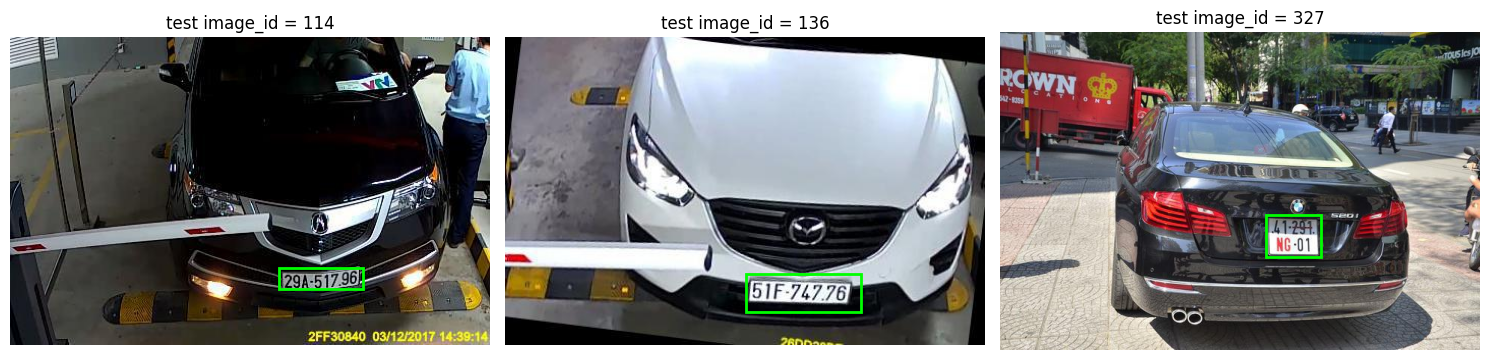

In [8]:
# Show the first 3 TEST images with their ground-truth boxes (green).
def to_pil(img_data):
    if isinstance(img_data, dict) and img_data.get("bytes") is not None:
        return Image.open(io.BytesIO(img_data["bytes"])).convert("RGB")
    if isinstance(img_data, Image.Image):
        return img_data.convert("RGB")
    return Image.open(img_data["path"]).convert("RGB")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, ax in enumerate(axes):
    row = test_df.iloc[i]
    ax.imshow(to_pil(row["image"]))
    for x, y, w, h in row["objects"]["bbox"]:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(f"test image_id = {row['image_id']}")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Preprocessing: COCO boxes to YOLO labels

Each box `[x, y, w, h]` (pixels) is clipped to the image, then converted to YOLO format
`class x_center y_center width height` (normalised to 0-1). There is a single class, id `0`.

In [9]:
def to_list(value):
    """Convert None / list / tuple / ndarray to an ordinary Python list."""
    if value is None:
        return []
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (list, tuple)):
        return list(value)
    return [value]


def convert_dataframe_to_yolo(df, split_name):
    image_dir = DATASET_DIR / "images" / split_name
    label_dir = DATASET_DIR / "labels" / split_name
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for _, row in df.iterrows():
        info = row["image"]
        original_name = Path(info.get("path") or f'{row["image_id"]}.jpg').name
        extension = Path(original_name).suffix or ".jpg"
        filename = f'{row["image_id"]}_{Path(original_name).stem}{extension}'  # prefix avoids collisions

        with open(image_dir / filename, "wb") as f:
            f.write(bytes(info["bytes"]))

        W, H = float(row["width"]), float(row["height"])
        boxes = to_list(row["objects"].get("bbox", []))
        cats  = to_list(row["objects"].get("category", []))
        if len(boxes) != len(cats):
            raise ValueError(f"bbox/category mismatch for image_id {row['image_id']}")

        ann = []
        for bbox in boxes:
            x_min, y_min, bw, bh = map(float, bbox)
            x1, y1 = max(0.0, x_min), max(0.0, y_min)                 # clip to image
            x2, y2 = min(W, x_min + bw), min(H, y_min + bh)
            if x2 - x1 <= 0 or y2 - y1 <= 0:                          # drop degenerate boxes
                continue
            ann.append(f"0 {(x1+x2)/(2*W):.6f} {(y1+y2)/(2*H):.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")

        (label_dir / f"{Path(filename).stem}.txt").write_text("\n".join(ann))

    print(f"{split_name}: converted {len(df)} records -> {label_dir}")


if not (DATASET_DIR / "labels" / "test").exists():
    for split, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
        convert_dataframe_to_yolo(df, split)
else:
    print("YOLO dataset already exists at", DATASET_DIR, "- skipping conversion.")

train: converted 6179 records -> /content/license_plate_dataset/labels/train
val: converted 1768 records -> /content/license_plate_dataset/labels/val
test: converted 885 records -> /content/license_plate_dataset/labels/test


In [10]:
yaml_path = DATASET_DIR / "data.yaml"
yaml_path.write_text(yaml.safe_dump({
    "path": str(DATASET_DIR), "train": "images/train", "val": "images/val", "test": "images/test",
    "nc": 1, "names": ["license_plate"],
}, sort_keys=False))
print(yaml_path.read_text())

path: /content/license_plate_dataset
train: images/train
val: images/val
test: images/test
nc: 1
names:
- license_plate



In [11]:
# Sanity check: every image has a label file; report empty labels.
for split in ["train", "val", "test"]:
    imgs   = list((DATASET_DIR / "images" / split).glob("*"))
    labels = list((DATASET_DIR / "labels" / split).glob("*.txt"))
    empty  = sum(1 for p in labels if p.stat().st_size == 0)
    print(f"{split}: {len(imgs)} images, {len(labels)} labels, {empty} empty label files")

train: 6179 images, 6179 labels, 0 empty label files
val: 1765 images, 1765 labels, 0 empty label files
test: 885 images, 885 labels, 0 empty label files


## 4. Model: pretrained YOLOv8n

YOLOv8n (nano) is initialised from COCO weights; the detection head is rebuilt for one class (349 of 355 tensors transfer).

In [13]:
model = YOLO("yolov8n.pt")
model.info()

WARNING ⚠️ Download failure, retrying 1/3 in 5s https://github.com/ultralytics/assets/releases/download/v8.4.0/yolov8n.pt... 504 Server Error: Gateway Time-out for url: https://github.com/ultralytics/assets/releases/download/v8.4.0/yolov8n.pt
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

## 5. Baselines

COCO-pretrained YOLOv8n has no license-plate class, so a zero-shot score is undefined. We use:

* **Baseline A:** the pretrained backbone after **1 epoch** of fine-tuning (read from `results.csv`).
* **Baseline B (optional):** the same architecture trained **from random initialisation** (`yolov8n.yaml`) with the same schedule. Set `RUN_BASELINE_SCRATCH = True` to produce it; it quantifies the benefit of pretraining.

In [15]:
def load_results_csv(path=RESULTS_CSV):
    if not Path(path).exists():
        print(f"{path} not found - place the training log there to enable the baseline table and curves.")
        return None
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    return df

res_df = load_results_csv()
if res_df is not None:
    cols = ["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]
    pick = res_df[res_df["epoch"].isin([1, 10, 25, int(res_df["epoch"].max())])][cols]
    pick.columns = ["epoch", "precision", "recall", "mAP50", "mAP50-95"]
    print("Validation metrics during fine-tuning (Baseline A = epoch 1, final = last epoch):")
    display(pick.round(4).reset_index(drop=True))

results/results.csv not found - place the training log there to enable the baseline table and curves.


In [16]:
if RUN_BASELINE_SCRATCH:
    scratch = YOLO("yolov8n.yaml")                       # random initialisation, no pretrained weights
    scratch_res = scratch.train(
        data=str(DATASET_DIR / "data.yaml"), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
        workers=2, patience=PATIENCE, amp=True, seed=SEED, pretrained=False,
        project=str(OUT_DIR), name="yolov8n_scratch", exist_ok=True)
    m = scratch.val(data=str(DATASET_DIR / "data.yaml"), split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE)
    print("Baseline B (from scratch) TEST  P=%.4f R=%.4f mAP50=%.4f mAP50-95=%.4f"
          % (m.box.mp, m.box.mr, m.box.map50, m.box.map))
else:
    print("Skipped (RUN_BASELINE_SCRATCH = False).")

Skipped (RUN_BASELINE_SCRATCH = False).


## 6. Training

Fine-tuning on the training split; the validation split is used for monitoring and for selecting `best.pt`.
**This cell takes about 72 minutes on a Colab T4.** It only runs when `RUN_TRAINING = True`.

In [22]:
if RUN_TRAINING:
    results = model.train(
        data=str(DATASET_DIR / "data.yaml"),
        epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=2, cache=False,
        patience=PATIENCE, amp=True, seed=SEED, deterministic=True,
        project=str(OUT_DIR), name=RUN_NAME, exist_ok=True,
    )
    WEIGHTS_PATH = Path(results.save_dir) / "weights" / "best.pt"
    print("Training finished. Best weights:", WEIGHTS_PATH)
else:
    print("Skipped training (RUN_TRAINING = False). Using weights at:", WEIGHTS_PATH)

Skipped training (RUN_TRAINING = False). Using weights at: /content/runs_license_plate/best.pt


In [23]:
if not Path(WEIGHTS_PATH).exists():
    raise FileNotFoundError(
        f"{WEIGHTS_PATH} not found. Either set RUN_TRAINING = True, or copy your trained best.pt there "
        "(or edit WEIGHTS_PATH in section 0).")
model = YOLO(str(WEIGHTS_PATH))
print("Loaded fine-tuned weights:", WEIGHTS_PATH)

Loaded fine-tuned weights: /content/runs_license_plate/best.pt


## 7. Training curves

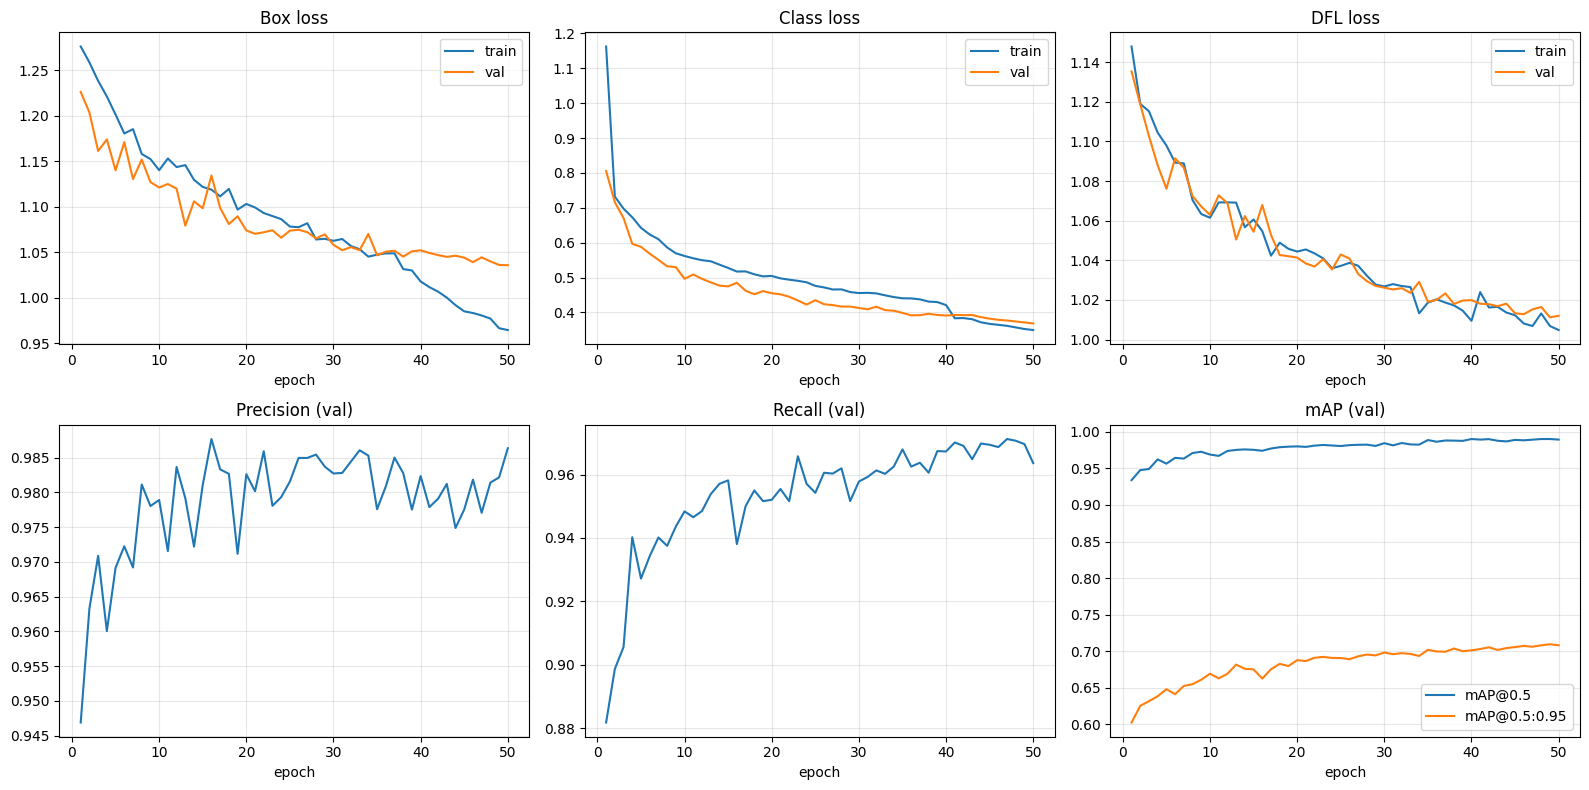

Best val mAP50 = 0.9902 at epoch 49; training time = 72.2 min


In [30]:
res_df = load_results_csv()
if res_df is not None:
    fig, ax = plt.subplots(2, 3, figsize=(16, 8))
    panels = [("train/box_loss", "val/box_loss", "Box loss"),
              ("train/cls_loss", "val/cls_loss", "Class loss"),
              ("train/dfl_loss", "val/dfl_loss", "DFL loss")]
    for a, (tr, va, title) in zip(ax[0], panels):
        a.plot(res_df["epoch"], res_df[tr], label="train"); a.plot(res_df["epoch"], res_df[va], label="val")
        a.set_title(title); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
    for a, (col, title) in zip(ax[1], [("metrics/precision(B)", "Precision (val)"),
                                       ("metrics/recall(B)", "Recall (val)")]):
        a.plot(res_df["epoch"], res_df[col]); a.set_title(title); a.set_xlabel("epoch"); a.grid(alpha=.3)
    ax[1, 2].plot(res_df["epoch"], res_df["metrics/mAP50(B)"], label="mAP@0.5")
    ax[1, 2].plot(res_df["epoch"], res_df["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
    ax[1, 2].set_title("mAP (val)"); ax[1, 2].set_xlabel("epoch"); ax[1, 2].legend(); ax[1, 2].grid(alpha=.3)
    plt.tight_layout(); plt.show()
    best = res_df.loc[res_df["metrics/mAP50(B)"].idxmax()]
    print(f"Best val mAP50 = {best['metrics/mAP50(B)']:.4f} at epoch {int(best['epoch'])}; "
          f"training time = {res_df['time'].iloc[-1]/60:.1f} min")

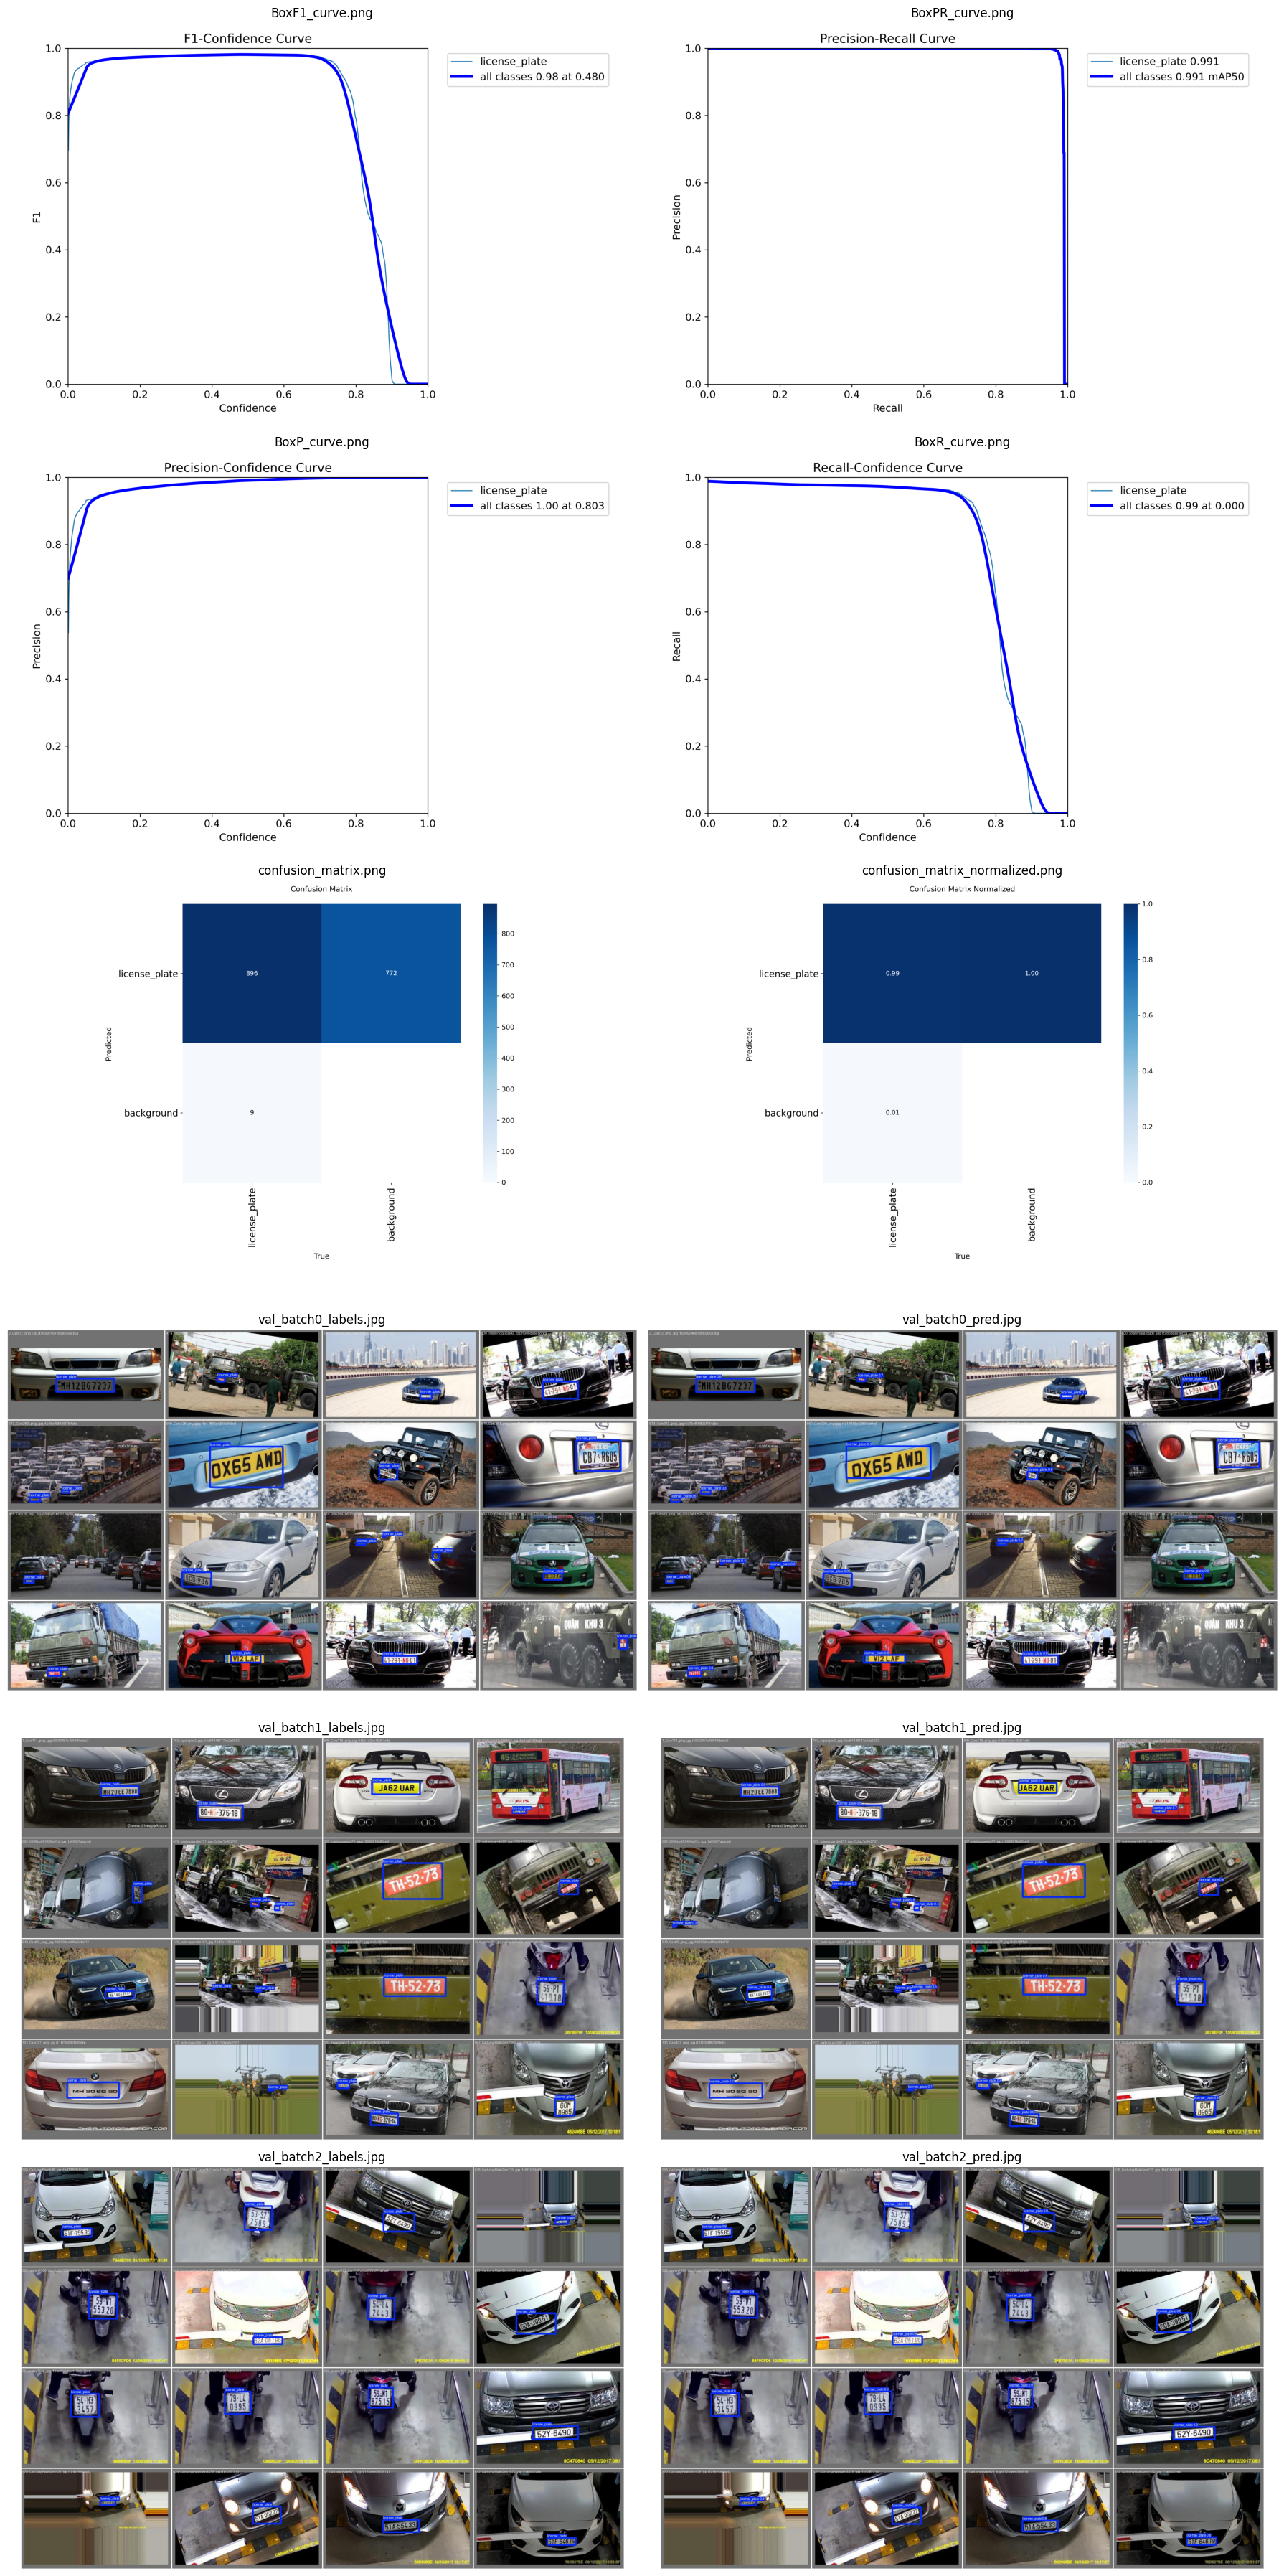

In [31]:
# Ultralytics' own evaluation plots (confusion matrix, PR / F1 curves) from the test evaluation run.
plots_dir = OUT_DIR / "test_evaluation"
if plots_dir.exists():
    files = sorted(p for p in plots_dir.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"})
    cols = 2; rows = math.ceil(len(files) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(18, 6 * rows)); axes = np.atleast_1d(axes).flatten()
    for a, p in zip(axes, files):
        a.imshow(Image.open(p)); a.set_title(p.name); a.axis("off")
    for a in axes[len(files):]:
        a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Run section 8 first to generate the evaluation plots.")

## 8. Evaluation on the held-out test split

The test split is used **once**, for the final numbers. Metrics: precision, recall, mAP@0.5 and mAP@0.5:0.95.

In [26]:
metrics = model.val(
    data=str(DATASET_DIR / "data.yaml"), split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE,
    plots=True, project=str(OUT_DIR), name="test_evaluation", exist_ok=True,
)
print("-------------------------------------")
print("Precision :", metrics.box.mp)
print("Recall    :", metrics.box.mr)
print("mAP50     :", metrics.box.map50)
print("mAP50-95  :", metrics.box.map)
print("Speed (ms/img):", metrics.speed)

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 999.0±418.6 MB/s, size: 21.9 KB)
val: Scanning /content/license_plate_dataset/labels/test... 885 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 885/885 2.0Kit/s 0.4s
val: New cache created: /content/license_plate_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 6.4it/s 8.7s
                   all        885        905       0.99      0.973      0.991      0.716
Speed: 0.9ms preprocess, 2.9ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs_license_plate/test_evaluation
-------------------------------------
Precision : 0.9902681171445229
Recall    : 0.9734806629834254
mAP50     : 0.9913763660245908
mAP50-95  : 0.7162023345563988
Speed (ms/img): {'pre

## 9. Error analysis

Predictions on the test split are matched to ground truth (greedy, by confidence, IoU >= `IOU_MATCH`):

* **True positive (TP):** prediction matches an unmatched ground-truth box.
* **False positive (FP):** prediction with no matching ground truth.
* **False negative (FN):** ground-truth plate with no matching prediction.
* **Loose box:** a TP with IoU below 0.75.

We then report errors per sub-collection (from the filename prefix) and save image galleries to `ERR_DIR`.

In [27]:
def load_gt(label_path, W, H):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            p = line.split()
            if len(p) == 5:
                _, xc, yc, bw, bh = map(float, p)
                boxes.append([(xc - bw/2) * W, (yc - bh/2) * H, (xc + bw/2) * W, (yc + bh/2) * H])
    return np.array(boxes, dtype=float).reshape(-1, 4)


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def match(pred, conf, gt, thr=IOU_MATCH):
    """Greedy matching by descending confidence. Returns (tp_ious, fp_idx, fn_idx)."""
    order = np.argsort(-conf)
    ious = iou_matrix(pred, gt)
    used, tp_ious, fp = set(), [], []
    for i in order:
        cand = [(ious[i, j], j) for j in range(len(gt)) if j not in used]
        best = max(cand, default=(0, -1))
        if best[0] >= thr:
            used.add(best[1]); tp_ious.append(best[0])
        else:
            fp.append(i)
    fn = [j for j in range(len(gt)) if j not in used]
    return tp_ious, fp, fn


# --- self-test of the matching logic (runs instantly) ---
_g = np.array([[10, 10, 50, 30], [100, 100, 150, 130]], float)
_p = np.array([[11, 10, 50, 31], [300, 300, 340, 320]], float)
_tp, _fp, _fn = match(_p, np.array([0.9, 0.8]), _g)
assert len(_tp) == 1 and _fp == [1] and _fn == [1], "matching self-test failed"
print("matching self-test passed")

matching self-test passed


In [28]:
test_images = sorted((DATASET_DIR / "images" / "test").glob("*"))
records, store = [], {}
for r in model.predict(source=[str(p) for p in test_images], conf=CONF_THRES, imgsz=IMGSZ,
                       batch=BATCH, device=DEVICE, stream=True, verbose=False):
    H, W = r.orig_shape
    path = Path(r.path)
    gt = load_gt(DATASET_DIR / "labels" / "test" / f"{path.stem}.txt", W, H)
    pred = r.boxes.xyxy.cpu().numpy(); conf = r.boxes.conf.cpu().numpy()
    tp_ious, fp, fn = match(pred, conf, gt)
    m = re.match(r"\d+_([A-Za-z]+?)\d*_", path.name)
    records.append({"image": path.name, "subset": m.group(1) if m else "other",
                    "n_gt": len(gt), "n_pred": len(pred), "TP": len(tp_ious), "FP": len(fp), "FN": len(fn),
                    "min_iou": min(tp_ious) if tp_ious else np.nan,
                    "gt_area_pct": 100 * float(np.mean([(b[2]-b[0])*(b[3]-b[1]) for b in gt]) / (W*H)) if len(gt) else np.nan})
    store[path.name] = (pred, conf, gt, tp_ious, fp, fn)

err = pd.DataFrame(records)
tp, fp_, fn_ = err.TP.sum(), err.FP.sum(), err.FN.sum()
print(f"Instances: {err.n_gt.sum()} | TP={tp} FP={fp_} FN={fn_}")
print(f"Precision={tp/(tp+fp_):.4f}  Recall={tp/(tp+fn_):.4f}   (at conf>={CONF_THRES}, IoU>={IOU_MATCH})")
print("Images with >=1 FN:", int((err.FN > 0).sum()), "| with >=1 FP:", int((err.FP > 0).sum()),
      "| loose boxes (min IoU<0.75):", int((err.min_iou < 0.75).sum()))

OutOfMemoryError: CUDA out of memory. Tried to allocate 4.05 GiB. GPU 0 has a total capacity of 14.56 GiB of which 2.24 GiB is free. Including non-PyTorch memory, this process has 12.32 GiB memory in use. Of the allocated memory 10.83 GiB is allocated by PyTorch, and 1.37 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
# Error rates per sub-collection and by plate size.
by = err.groupby("subset").agg(images=("image", "count"), plates=("n_gt", "sum"),
                               FN=("FN", "sum"), FP=("FP", "sum"), loose=("min_iou", lambda s: int((s < 0.75).sum())))
by["miss_rate_%"] = (100 * by.FN / by.plates).round(2)
display(by.sort_values("plates", ascending=False))

err["size_bin"] = pd.qcut(err["gt_area_pct"], 4, labels=["smallest 25%", "25-50%", "50-75%", "largest 25%"])
display(err.groupby("size_bin", observed=True).agg(plates=("n_gt", "sum"), FN=("FN", "sum"), FP=("FP", "sum")))
err.to_csv(ERR_DIR / "test_error_table.csv", index=False)

In [ ]:
def draw(name, ax, title):
    pred, conf, gt, *_ = store[name]
    ax.imshow(Image.open(DATASET_DIR / "images" / "test" / name).convert("RGB"))
    for b in gt:   ax.add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="lime", lw=2))
    for b, c in zip(pred, conf):
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="red", lw=2, ls="--"))
        ax.text(b[0], max(b[1]-3, 8), f"{c:.2f}", color="red", fontsize=8)
    ax.set_title(title, fontsize=8); ax.axis("off")


def gallery(names, title, fname, ncols=4):
    if not names:
        print(f"{title}: none found"); return
    nrows = math.ceil(len(names) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.6 * nrows)); axes = np.atleast_1d(axes).flatten()
    for ax, n in zip(axes, names):
        draw(n, ax, n[:34])
    for ax in axes[len(names):]:
        ax.axis("off")
    fig.suptitle(title + "  (green = ground truth, red dashed = prediction)")
    plt.tight_layout(); fig.savefig(ERR_DIR / fname, dpi=120); plt.show()


gallery(err[err.FN > 0].image.tolist()[:8],  "False negatives (missed plates)",       "false_negatives.png")
gallery(err[err.FP > 0].image.tolist()[:8],  "False positives (spurious boxes)",     "false_positives.png")
gallery(err.sort_values("min_iou").dropna(subset=["min_iou"]).query("min_iou < 0.75").image.tolist()[:8],
        "Loosest matched boxes (IoU < 0.75)", "loose_boxes.png")

**Write-up prompt (fill in after running the cells above):**
list 3-6 concrete failure cases with the image name, what went wrong (small, blurred, oblique, occluded, annotation noise, text-like clutter) and one mitigation each. Copy the galleries from `outputs/errors/` into the report, Section 7.

## 10. Inference demo

Results saved to /content/runs_license_plate/test_predictions
882 labels saved to /content/runs_license_plate/test_predictions/labels


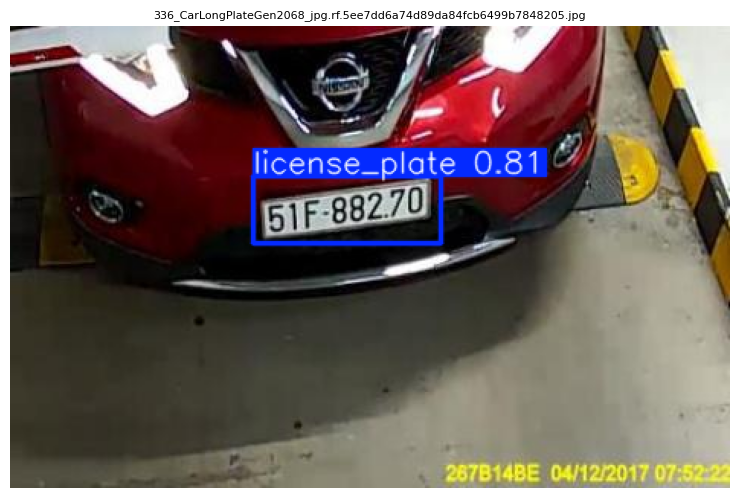

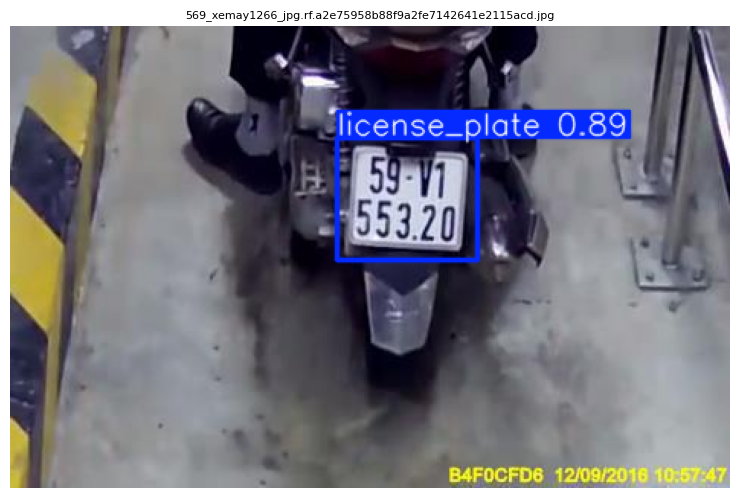

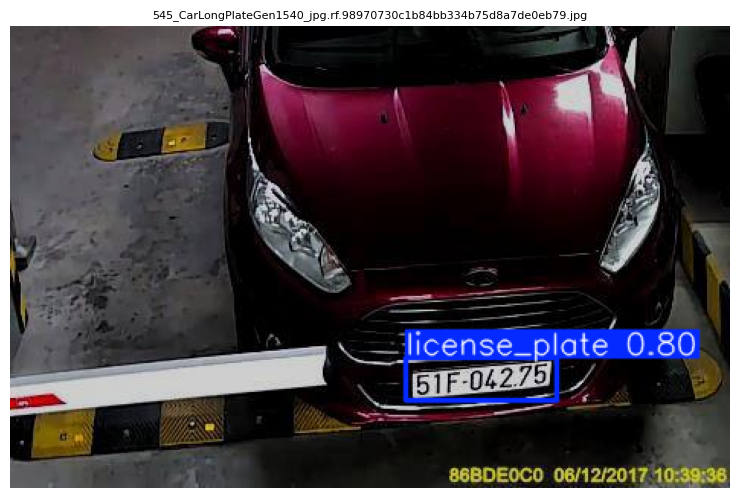

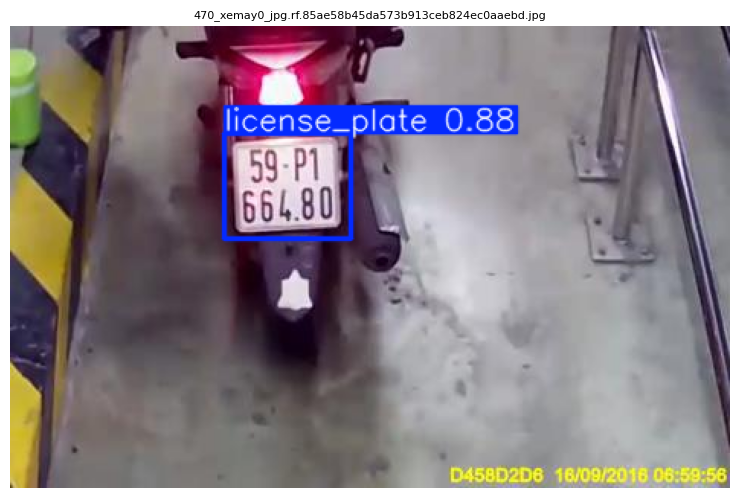

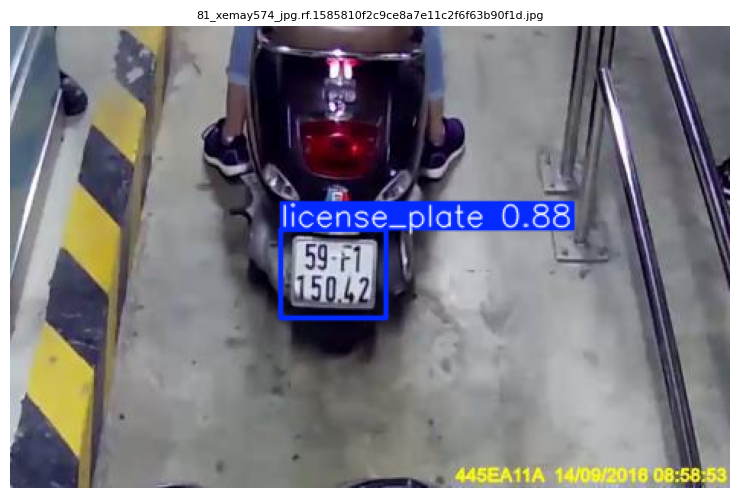

In [29]:
prediction_results = model.predict(
    source=str(DATASET_DIR / "images" / "test"), conf=CONF_THRES, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
    save=True, save_txt=True, save_conf=True, project=str(OUT_DIR), name="test_predictions",
    exist_ok=True, verbose=False,
)
sample = random.sample(prediction_results, min(5, len(prediction_results)))
for result in sample:
    plt.figure(figsize=(10, 6)); plt.imshow(result.plot()[..., ::-1]); plt.axis("off")
    plt.title(Path(result.path).name, fontsize=8); plt.show()

In [ ]:
# Single-image demo: pick any image path (here: the first test image).
one = sorted((DATASET_DIR / "images" / "test").glob("*"))[0]
r = model.predict(source=str(one), conf=CONF_THRES, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
plt.figure(figsize=(12, 7)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off"); plt.title(one.name); plt.show()
print("Detections:", [(box.xyxy[0].tolist(), float(box.conf)) for box in r.boxes])

## 11. Extension: reading the plate with OCR (outside the project scope)

The detector's crops are passed to a **pretrained, un-tuned EasyOCR English model**.
The dataset has **no ground-truth plate text**, so OCR accuracy cannot be measured; results are qualitative.

*Observed in the original run over all 885 test images:* a plate was detected in 881; OCR returned no text for 381 images and some text for 504, many of them visibly garbled. Detection is not the bottleneck; recognition is.

In [ ]:
if RUN_OCR_DEMO:
    %pip install -q easyocr opencv-python

In [ ]:
if RUN_OCR_DEMO:
    import cv2, easyocr
    reader = easyocr.Reader(["en"], gpu=(DEVICE == 0))

    def detect_and_read_plate(image_path):
        image = cv2.imread(str(image_path))
        if image is None:
            raise ValueError(f"Could not load image: {image_path}")
        detections = []
        for result in model.predict(source=image, conf=CONF_THRES, verbose=False):
            for box in result.boxes:
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                crop = image[y1:y2, x1:x2]
                if crop.size == 0:
                    continue
                text = " ".join(t for _, t, c in reader.readtext(crop, detail=1) if c > 0.3)
                detections.append({"bbox": (x1, y1, x2, y2), "text": text})
                cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(image, text, (x1, max(y1 - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        return image, detections

In [ ]:
if RUN_OCR_DEMO:
    ocr_dir = ROOT / "ocr_predictions"; ocr_dir.mkdir(exist_ok=True)
    all_imgs = sorted((DATASET_DIR / "images" / "test").glob("*"))
    chosen = random.sample(all_imgs, min(10, len(all_imgs)))          # demo on 10 random test images

    n_empty = 0
    for p in chosen:
        out_img, dets = detect_and_read_plate(p)
        cv2.imwrite(str(ocr_dir / p.name), out_img)
        texts = [d["text"] for d in dets]
        n_empty += int(not any(texts))
        print(f"{p.name[:40]:40s} -> {texts if dets else 'NO PLATE DETECTED'}")
    print(f"\nOCR returned empty text for {n_empty}/{len(chosen)} sampled images")

    for p in chosen[:5]:
        orig_img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        pred_img = cv2.cvtColor(cv2.imread(str(ocr_dir / p.name)), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(14, 5))
        plt.subplot(1, 2, 1); plt.imshow(orig_img); plt.title("Original"); plt.axis("off")
        plt.subplot(1, 2, 2); plt.imshow(pred_img); plt.title("YOLO + OCR"); plt.axis("off")
        plt.suptitle(p.name, fontsize=8); plt.tight_layout(); plt.show()

## 12. Summary, limitations and AI-use disclosure

**Results (from the executed run)**

| Split | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|---|
| Validation, epoch 1 (Baseline A) | 0.947 | 0.882 | 0.934 | 0.602 |
| Validation, epoch 50 (final) | 0.986 | 0.964 | 0.989 | 0.708 |
| **Test (final model)** | **0.990** | **0.973** | **0.991** | **0.716** |

Inference: about 2.7 ms per image on a Tesla T4 (plus 0.7 ms pre- and 1.2 ms post-processing).

**Limitations**
1. Narrow domain: mostly one region's plate styles; Pakistani plates, night scenes and heavy blur are untested.
2. Possible near-duplicate leakage between splits (Roboflow-style augmented variants); no duplicate audit was run.
3. Every image contains a plate, so false alarms on plate-free scenes are not measured.
4. Single run, single seed, no confidence intervals.
5. OCR has no ground truth and is evaluated qualitatively only.
6. Three validation records are lost on conversion because of repeated `image_id` filenames (Section 2 shows the duplicate count).

**Ethics:** plate data can identify vehicle owners; use only for lawful, proportionate purposes, minimise retention, keep a human in the loop for enforcement, and respect the dataset licence.

**AI-use disclosure:** pretrained YOLOv8n and EasyOCR models are used as components. A generative AI assistant (Claude, Anthropic) helped restructure this notebook and draft documentation. All experiment results come from the team's own executed runs. *Team: edit this statement to match what each member actually did.*

Actual un-AIEdited notebook:https://colab.research.google.com/drive/1GpngoZxTffP_gd9aaVEO4jTpbJtgR9s8?usp=sharing